In [12]:
import pandas as pd
import numpy as np
import emcee
from scipy.stats import gaussian_kde
import sys
from pathlib import Path

project_dir = Path.cwd()
if not (project_dir / "plot_style.py").exists():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from plot_style import *

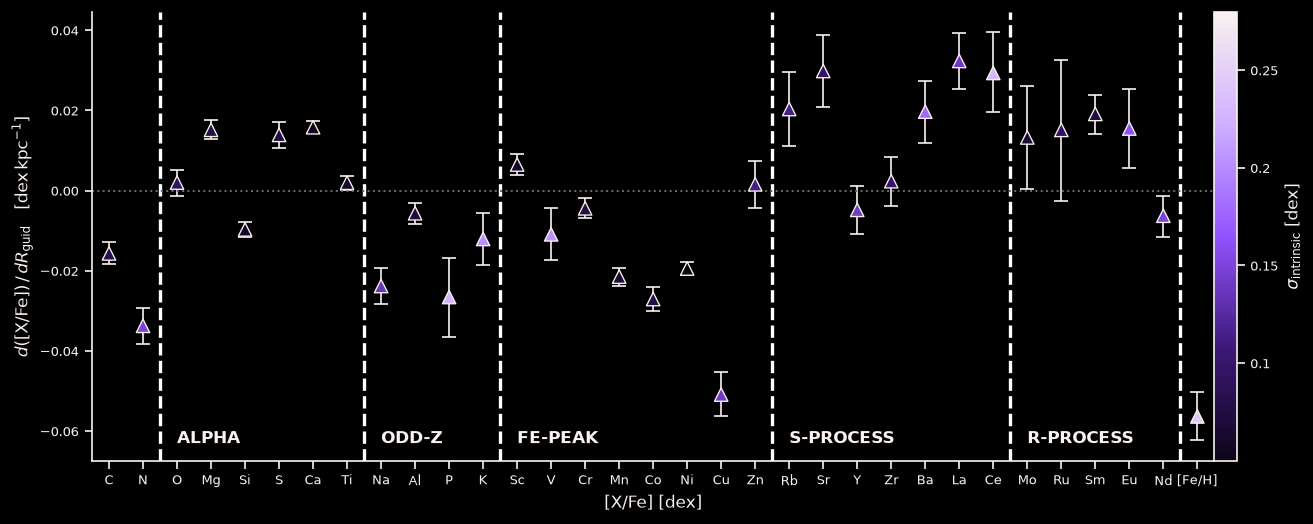

In [13]:
dark()

cat = pd.read_csv("abund_grads.csv")

# synthesis groupings
alpha = ["O", "Mg", "Si", "S", "Ca", "Ti"]   # CCSNe 
odd_z = ["Na", "Al", "P", "K"]   # unclear
fe_peak = ["Sc", "V", "Cr", "Mn", "Co", "Ni", "Cu", "Zn"]   # Sne Ia
s_proc = ["Rb", "Sr", "Y", "Zr", "Ba", "La", "Ce"]   # AGBs
r_proc = ["Mo", "Ru", "Sm", "Eu", "Nd"]    # NS mergers (+ CCSNe)

full_el = ["C"] + ["N"] + alpha + odd_z + fe_peak + s_proc + r_proc + ["Fe"]

order = {el: i for i, el in enumerate(full_el)}

cat = (
    cat.assign(order=cat["element"].map(order))
    .sort_values("order")
    .drop(columns="order")
    .reset_index(drop=True)
)

# figure setup
fig, ax = plt.subplots(figsize=(12, 4.5))

def format_label(el):
    if el == "Fe":
        return "$\mathrm{[Fe/H]}$"
    else:
        return rf"$\mathrm{{[{el}/Fe]}}$"

#x_labels = [format_label(el) for el in full_el]
x_labels = full_el[:-1]+[r"$\mathrm{[Fe/H]}$"]
x_pos = np.arange(len(x_labels))
barriers = [2-0.5, 2+len(alpha)-0.5, 2+len(alpha)+len(odd_z)-0.5, 2+len(alpha)+len(odd_z)+len(fe_peak)-0.5,
            2+len(alpha)+len(odd_z)+len(fe_peak)+len(s_proc)-0.5, 2+len(alpha)+len(odd_z)+len(fe_peak)+len(s_proc)+len(r_proc)-0.5]
plt.errorbar(x_pos, cat["d_x_fe"], yerr=[cat["lower_d_x_fe"], cat["upper_d_x_fe"]],
             ecolor=cream, ls="none", fmt="none", capsize=4, zorder=2, elinewidth=1)
plt.scatter(x_pos, cat["d_x_fe"], c=cat["sig_x_fe"], edgecolors=cream, lw=0.8, 
            s=65, cmap=cmap_dark_purple, zorder=3, vmin=0.05, vmax=0.28, marker="^")
for xval in barriers:
    plt.axvline(xval, lw=2, ls="--", c="white", marker="")
plt.axhline(0, lw=1.2, ls=":", c="DimGrey", marker="")
plt.text(barriers[0]+0.5, -0.063, "ALPHA", fontweight="bold", ha="left", fontsize=10)
plt.text(barriers[1]+0.5, -0.063, "ODD-Z", fontweight="bold", ha="left", fontsize=10)
plt.text(barriers[2]+0.5, -0.063, "FE-PEAK", fontweight="bold", ha="left", fontsize=10)
plt.text(barriers[3]+0.5, -0.063, "S-PROCESS", fontweight="bold", ha="left", fontsize=10)
plt.text(barriers[4]+0.5, -0.063, "R-PROCESS", fontweight="bold", ha="left", fontsize=10)
ax.set_xticks(x_pos)
ax.set_xticklabels(x_labels)
#ax.set_xticklabels(x_labels, rotation=45, ha="right")
plt.xlabel(r"$\mathrm{[X/Fe]}$ [dex]")
plt.ylabel(r"$d\left( \mathrm{[X/Fe]} \right)\,/\,dR_\mathrm{guid}$   [$\mathrm{dex}\,\mathrm{kpc}^{-1}$]")
plt.xlim(x_pos[0]-0.5, x_pos[-1]+0.5)
cbar = plt.colorbar(label=r"$\sigma_\mathrm{intrinsic}$ [dex]", pad=0)
cbar.set_ticks([0.1, 0.15, 0.2, 0.25])
cbar.set_ticklabels(["0.1", "0.15", "0.2", "0.25"])
plt.savefig("OLD_TI_abund_plot.png", dpi=200)
plt.tight_layout()
plt.show()


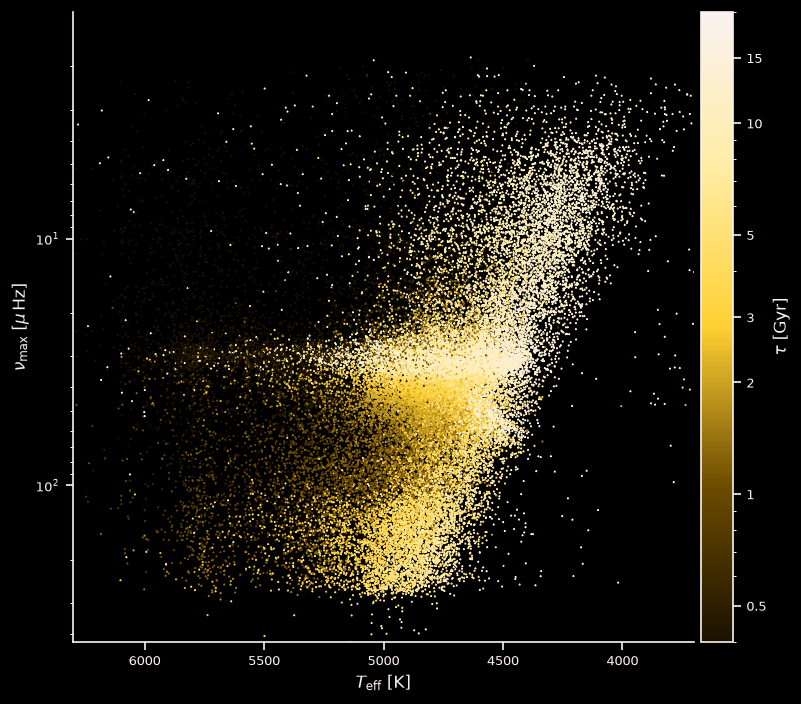

In [14]:
results = pd.read_csv("complete_TD_catalogue.csv")
plt.figure(figsize=(7, 6))
plt.scatter(results["teff"], results["numax"], c=(results["age"]), s=0.1, cmap=cmap_dark_gold, norm=LogNorm(vmin=0.4, vmax=20))
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
plt.xlim(6300, 3700)
plt.ylim(430, 1.2)
#plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$T_\mathrm{eff}$ [K]")
plt.ylabel(r"$\nu_\mathrm{max}$ [$\mu\,$Hz]")
cbar = plt.colorbar(label=r"$\tau$ [Gyr]", pad=0.01)
cbar.set_ticks([0.5, 1, 2, 3, 5, 10, 15])
cbar.set_ticklabels(["0.5", "1", "2", "3", "5", "10", "15"])
plt.tight_layout()
plt.savefig("OLD_asteroHRD.png", dpi=200)
plt.show()

In [15]:
def linreg(x_fe, Rg, x_fe_err=None, nwalkers=32, nsteps=5000):
    """
    Linear regression with intrinsic scatter:
        x_fe = m * Rg + b + Gaussian scatter

    Parameters
    ----------
    x_fe : array
    Rg   : array
    xerr : array or None (measurement errors on x_fe)
    """

    x_fe = np.asarray(x_fe)
    Rg = np.asarray(Rg)

    if x_fe_err is None:
        x_fe_err = np.zeros_like(x_fe)
    else:
        x_fe_err = np.asarray(x_fe_err)

    # ---- model ----
    def log_prior(theta):
        m, b, log_sigma = theta
        sigma = np.exp(log_sigma)

        # broad but finite priors
        if not (-100 < m < 100 and -100 < b < 100 and -10 < log_sigma < 5):
            return -np.inf
        return 0.0

    def log_likelihood(theta):
        m, b, log_sigma = theta
        sigma = np.exp(log_sigma)

        model = m * Rg + b
        var = sigma**2 + x_fe_err**2

        return -0.5 * np.sum((x_fe - model)**2 / var + np.log(var))

    def log_probability(theta):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        return lp + log_likelihood(theta)

    # ---- initial guess ----
    m0, b0 = np.polyfit(Rg, x_fe, 1)
    sigma0 = np.std(x_fe - (m0 * Rg + b0))

    ndim = 3
    pos = np.array([m0, b0, np.log(sigma0)]) + 1e-3 * np.random.randn(nwalkers, ndim)

    # ---- sampler ----
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability)
    sampler.run_mcmc(pos, nsteps, progress=True)

    # ---- flatten chains ----
    flat = sampler.get_chain(discard=nsteps//2, flat=True)

    # posterior samples
    m_samples = flat[:, 0]
    b_samples = flat[:, 1]
    sigma_samples = np.exp(flat[:, 2])

    # medians
    m = np.median(m_samples)
    b = np.median(b_samples)
    sigma_int = np.median(sigma_samples)

    # 16th and 84th percentiles
    m16, m84 = np.percentile(m_samples, [16, 84])

    return {
        "slope": m,
        "slope_err": (m - m16, m84 - m),
        "intercept": b,
        "sigma_int": sigma_int
    }

In [16]:
age_int = 1.5

Vtot = np.sqrt(results["U"]**2 + results["V"]**2 + results["W"]**2)

thin = results[
    (Vtot < 50) &
    (results["zmax"] < 300)
]

ages = [(0,0.5), (0.5,1), (1,1.5), (1.5,2), (2,2.75), (2.75,3.5), (3.5,4.5), (4.5,5.5), (5.5,6.5), (6.5,8), (8,9.5), (9.5,11), (11,13), (13,20)]

cats = []
a = 0
for vals in ages:
    a = vals[0]
    b = vals[1]
    if a == 13:
        sub = thin[(thin["age"] > a)]
    else:
        sub = thin[(thin["age"] > a) & (thin["age"] <= b)]
    cats.append(sub["gaiadr3_id"].astype("int64"))
    a = b

In [17]:
names = []
age_mean = []
feh_grad = []
feh_lo = []
feh_hi = []
feh_scat = []
feh_int = []
afe_grad = []
afe_lo = []
afe_hi = []
afe_scat = []
afe_int = []
mass_mean = []

for a in range(len(cats)):
    ind = cats[a]
    arr = thin[thin["gaiadr3_id"].isin(ind)]
    print(len(arr))
    age_mean.append(np.mean(arr["age"]))
    mass_mean.append(np.mean(arr["mass"]))
    age_mn = ages[a][0]
    age_mx = ages[a][1]
    if a == 0:
        names.append(rf"$\tau \leq {age_mx:.1f}\,\mathrm{{Gyr}}$")
    elif a == 9:
        names.append(rf"$\tau > {age_mn:.1f}\,\mathrm{{Gyr}}$")
    else:
        names.append(rf"${age_mn:.1f} < \tau \leq {age_mx:.1f}\,\mathrm{{Gyr}}$")
    res = linreg(arr["fe_h"], arr["Rg"], arr["e_fe_h"])
    feh_grad.append(res["slope"])
    feh_lo.append(res["slope_err"][0])
    feh_hi.append(res["slope_err"][1])
    feh_scat.append(res["sigma_int"])
    feh_int.append(res["intercept"])
    res = None
    arr = arr.notna()
    res = linreg(arr["a_fe"], arr["Rg"], arr["e_a_fe"])
    afe_grad.append(res["slope"])
    afe_lo.append(res["slope_err"][0])
    afe_hi.append(res["slope_err"][1])
    afe_scat.append(res["sigma_int"])
    afe_int.append(res["intercept"])
    res = None
    

199


100%|██████████| 5000/5000 [00:02<00:00, 2463.65it/s]
/tmp/ipykernel_292737/215526930.py:47: RankWarning: Polyfit may be poorly conditioned
  m0, b0 = np.polyfit(Rg, x_fe, 1)
100%|██████████| 5000/5000 [00:01<00:00, 2737.43it/s]


233


100%|██████████| 5000/5000 [00:01<00:00, 2533.88it/s]
/tmp/ipykernel_292737/215526930.py:47: RankWarning: Polyfit may be poorly conditioned
  m0, b0 = np.polyfit(Rg, x_fe, 1)
100%|██████████| 5000/5000 [00:01<00:00, 2586.08it/s]


269


100%|██████████| 5000/5000 [00:02<00:00, 2415.57it/s]
/tmp/ipykernel_292737/215526930.py:47: RankWarning: Polyfit may be poorly conditioned
  m0, b0 = np.polyfit(Rg, x_fe, 1)
100%|██████████| 5000/5000 [00:01<00:00, 2538.14it/s]


... (18 outputs left out)

133


100%|██████████| 5000/5000 [00:01<00:00, 2529.71it/s]
/tmp/ipykernel_292737/215526930.py:47: RankWarning: Polyfit may be poorly conditioned
  m0, b0 = np.polyfit(Rg, x_fe, 1)
100%|██████████| 5000/5000 [00:01<00:00, 2813.08it/s]


66


100%|██████████| 5000/5000 [00:01<00:00, 2740.14it/s]
/tmp/ipykernel_292737/215526930.py:47: RankWarning: Polyfit may be poorly conditioned
  m0, b0 = np.polyfit(Rg, x_fe, 1)
100%|██████████| 5000/5000 [00:01<00:00, 2828.58it/s]


In [18]:
# res = linreg(arr["fe_h"], arr["Rg"], arr["e_fe_h"])
# feh_grad.append(res["slope"])
# feh_lo.append(res["slope_err"][0])
# feh_hi.append(res["slope_err"][1])
# feh_scat.append(res["sigma_int"])
# feh_int.append(res["intercept"])

In [19]:
grads = pd.DataFrame({
    "age_str": names,
    "age_mean": age_mean,
    "mass_mean": mass_mean,
    "feh_grad": feh_grad,
    "feh_lo": feh_lo,
    "feh_hi": feh_hi,
    "feh_scat": feh_scat,
    "feh_int": feh_int,
    "afe_grad": afe_grad,
    "afe_lo": afe_lo,
    "afe_hi": afe_hi,
    "afe_scat": afe_scat,
    "afe_int": afe_int
})

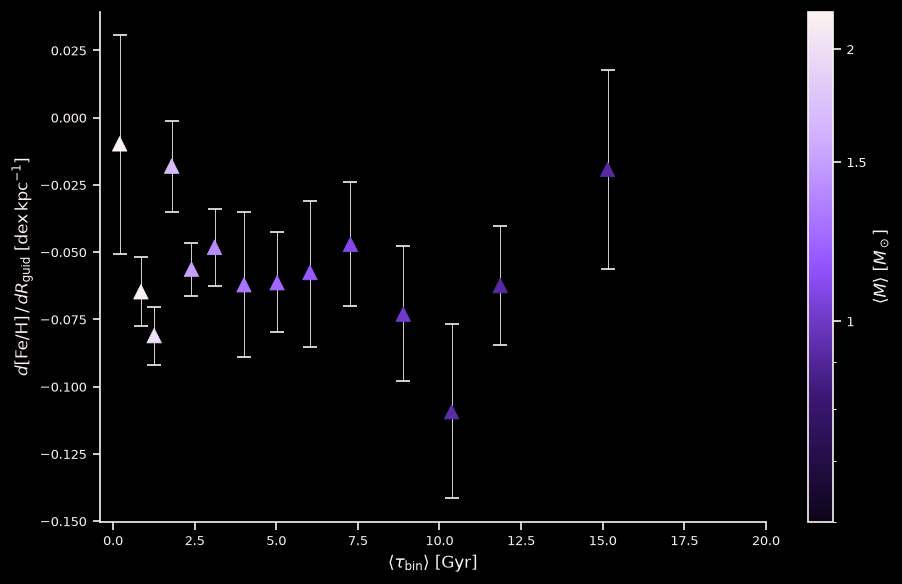

In [21]:
plt.figure(figsize=(8, 5))
plt.errorbar(grads["age_mean"], grads["feh_grad"], yerr=[grads["feh_lo"], grads["feh_hi"]],
             ecolor=cream, ls="none", markersize=0, capsize=4, elinewidth=0.5, zorder=1)
plt.scatter(grads["age_mean"], grads["feh_grad"], c=grads["mass_mean"], cmap=cmap_dark_purple, s=75, 
            zorder=2, norm=LogNorm(vmin=0.6, vmax=2.2), lw=0.5, ls="", edgecolors=None, marker="^")
cbar = plt.colorbar(label=r"$\langle M \rangle$ [$M_\odot$]")
cbar.set_ticks([1, 1.5, 2])
cbar.set_ticklabels(["1", "1.5", "2"])

plt.xlabel(r"$\langle\tau_\mathrm{bin}\rangle$ [Gyr]")
plt.ylabel(r"$d\mathrm{[Fe/H]}\,/\,dR_\mathrm{guid}$ [$\mathrm{dex}\,\mathrm{kpc}^{-1}$]")
plt.xlim(-0.4, 20)
cbar.ax.yaxis.set_minor_formatter(NullFormatter())
plt.tight_layout()
plt.savefig("OLD_evolve_feh.png", dpi=200)

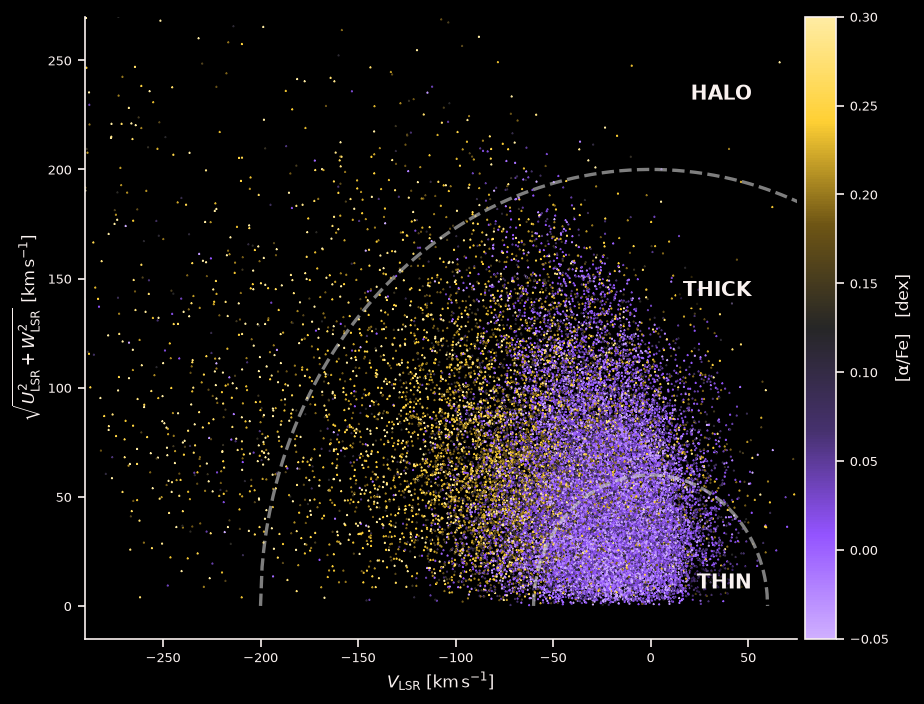

In [22]:
full = pd.read_csv("complete_TI_catalogue.csv").astype({"gaiadr3_id": "int64"})

plt.figure(figsize=(8, 6))

for v_lim in [60, 200]:
    x = np.linspace(-v_lim, v_lim, 500)
    y = np.sqrt(v_lim**2 - x**2)
    plt.plot(x, y, c="LightGrey", alpha=0.6, marker="", ls="--", lw=2)

U = np.array(full["U"])
V = np.array(full["V"])
W = np.array(full["W"])

toomre = ((U)**2 + (W)**2)**(0.5)
plt.scatter(V, toomre, s=0.15, c=full["a_fe"], cmap=cmap_dark_div, vmin=-0.05, vmax=0.3)
plt.xlabel(r"$V_\mathrm{LSR}$ [$\mathrm{km}\,\mathrm{s}^{-1}$]")
plt.ylabel(r"$\sqrt{U_\mathrm{LSR}^2 + W_\mathrm{LSR}^2}$ [$\mathrm{km}\,\mathrm{s}^{-1}$]")
plt.text(52, 8, "THIN", fontweight="bold", ha="right", fontsize=12, bbox=dict(facecolor="k", alpha=0.6, edgecolor="none", boxstyle="round", pad=0.35))
plt.text(52, 142, "THICK", fontweight="bold", ha="right", fontsize=12, bbox=dict(facecolor="k", alpha=0.6, edgecolor="none", boxstyle="round", pad=0.35))
plt.text(52, 232, "HALO", fontweight="bold", ha="right", fontsize=12, bbox=dict(facecolor="k", alpha=0.6, edgecolor="none", boxstyle="round", pad=0.35))
plt.xlim(-290, 75)
plt.ylim(-15, 270)
plt.colorbar(label=r"$\mathrm{[\alpha/Fe]}$   [dex]", pad=0.01)
plt.tight_layout()
plt.savefig("OLD_toomre_diagram.png", dpi=200)
plt.show()